In [16]:
from dotenv import load_dotenv
load_dotenv()

import sys
sys.path.append("../streamlit_app")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from utils import load_data

# Plots plus grands par défaut
plt.rcParams["figure.figsize"] = (10, 5)

# Vider le cache Streamlit avant de recharger
load_data.clear()

# Chargement des deux tables (via Postgres, pas via CSV)
df_km = load_data("data/activities_km.csv")
df_act = load_data("data/activities_clean.csv")
print(f"df_km  : {df_km['activity_id'].nunique()} sorties")
print(f"df_act : {len(df_act)} sorties")

print(f"df_km  : {len(df_km):>4} lignes ({df_km['activity_id'].nunique()} sorties)")
print(f"df_act : {len(df_act):>4} sorties")
print(f"\nColonnes df_km : {list(df_km.columns)}")
df_km.head(-1)

2026-09-27 12:22:27.377 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-09-27 12:22:30.377 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


df_km  : 131 sorties
df_act : 131 sorties
df_km  :  783 lignes (131 sorties)
df_act :  131 sorties

Colonnes df_km : ['activity_id', 'km_index', 'km_distance_m', 'pace_min_per_km', 'moving_time_s', 'elev_gain_m', 'elev_loss_m', 'elev_delta_m', 'avg_grade_pct', 'avg_heartrate', 'avg_cadence', 'distance_before_km', 'is_partial', 'fraction_completed', 'elev_gain_before_m']


,activity_id,km_index,km_distance_m,pace_min_per_km,moving_time_s,elev_gain_m,elev_loss_m,elev_delta_m,avg_grade_pct,avg_heartrate,avg_cadence,distance_before_km,is_partial,fraction_completed,elev_gain_before_m
0,11346532154,1,997.5,4.611529,276.0,8.870000,0.296250,8.590909,0.861244,NaN,NaN,0.0,False,0.333333,0.000000
1,11346532154,2,997.7,4.293208,257.0,0.200000,2.587159,-2.570909,-0.257684,NaN,NaN,1000.0,False,0.666667,8.870000
2,11346532154,3,568.7,4.161538,142.0,1.755000,7.197727,-5.442727,-0.957047,NaN,NaN,2000.0,True,1.000000,9.070000
3,11351598892,1,997.5,4.427736,265.0,2.775000,11.393087,-8.615455,-0.863705,NaN,NaN,0.0,False,0.250000,0.000000
4,11351598892,2,996.1,4.467423,267.0,3.699542,1.060000,2.702727,0.271331,NaN,NaN,1000.0,False,0.500000,2.775000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
777,20279714785,2,994.9,5.678963,339.0,3.603182,6.935000,-3.571818,-0.359013,156.626471,79.173529,1000.0,False,0.285714,2.548162
778,20279714785,3,998.2,5.743672,344.0,6.487917,3.525000,2.921818,0.292709,159.559420,79.353623,2000.0,False,0.428571,6.151344
779,20279714785,4,997.8,5.679161,340.0,8.885000,0.345000,8.703636,0.872283,171.463343,80.275660,3000.0,False,0.571429,12.639261
780,20279714785,5,994.8,5.193674,310.0,6.345516,0.020000,6.537273,0.657144,177.128617,78.909968,4000.0,False,0.714286,21.524261


# Vérification de la table activities_km

## 1. Cohérence interne

In [17]:
print("Colonnes df_act :", list(df_act.columns))
df_act.head(2)

Colonnes df_act : ['id', 'name', 'sport_type', 'manual', 'flagged', 'start_date_local', 'moving_time_seconds', 'average_speed_m_s', 'max_speed_m_s', 'total_elevation_gain_m', 'elev_high_m', 'elev_low_m', 'average_heartrate', 'max_heartrate', 'pr_count', 'suffer_score', 'day_of_week', 'date_fr', 'hour_fr', 'date', 'hour', 'month', 'year', 'distance_km', 'pace_min_km', 'pause_seconds', 'weather_temperature', 'weather_humidity', 'weather_precipitation', 'weather_code']


,id,name,sport_type,manual,flagged,start_date_local,moving_time_seconds,average_speed_m_s,max_speed_m_s,total_elevation_gain_m,...,hour,month,year,distance_km,pace_min_km,pause_seconds,weather_temperature,weather_humidity,weather_precipitation,weather_code
0,20279714785,Course à pied le midi,Run,False,False,2026-09-22 12:22:22+00:00,2114,3.123,4.92,27.9,...,12,2026-09,2026,6.6018,5.336749,0,18.6,54.0,0.0,0.0
1,20251558602,Lunch Run,Run,False,False,2026-09-20 11:32:51+00:00,697,3.590,5.36,7.6,...,11,2026-09,2026,2.5019,4.642526,0,17.8,93.0,0.0,3.0


In [18]:
# --- Agrégation depuis df_km ---
def hr_time_weighted(g):
    """FC moyenne pondérée par le temps passé sur chaque km (allure * distance)."""
    valid = g.dropna(subset=["avg_heartrate"])
    if len(valid) == 0:
        return np.nan
    weights = valid["pace_min_per_km"] * valid["km_distance_m"] / 1000
    return np.average(valid["avg_heartrate"], weights=weights)

km_agg = df_km.groupby("activity_id").apply(lambda g: pd.Series({
    "dist_km_sum_m": g["km_distance_m"].sum(),
    "n_splits": len(g),
    "n_full_splits": (~g["is_partial"]).sum(),
    "hr_time_weighted": hr_time_weighted(g),
})).reset_index()

# --- Merge avec df_act ---
check = km_agg.merge(
    df_act[["id", "distance_km", "moving_time_seconds", "average_heartrate"]],
    left_on="activity_id", right_on="id", how="left"
)

# --- Écarts ---
check["dist_recompute_km"] = check["dist_km_sum_m"] / 1000
check["dist_diff_pct"]     = 100 * (check["dist_recompute_km"] - check["distance_km"]) / check["distance_km"]
check["hr_diff_bpm"]       = check["hr_time_weighted"] - check["average_heartrate"]
check["expected_splits"]   = np.ceil(check["distance_km"]).fillna(0).astype(int)
check["splits_diff"]       = check["n_splits"] - check["expected_splits"]

# --- Résumé ---
print("=== 1. DISTANCE ===")
print(check["dist_diff_pct"].describe().round(3))
print(f"Sorties avec |écart| > 1% : {(check['dist_diff_pct'].abs() > 1).sum()}/{len(check)}")
print(f"Sorties avec |écart| > 5% : {(check['dist_diff_pct'].abs() > 5).sum()}/{len(check)}")

print("\n=== 2. FC (pondérée par temps) ===")
print(check["hr_diff_bpm"].describe().round(2))
n_hr = check["hr_diff_bpm"].notna().sum()
print(f"Sorties avec FC dispo : {n_hr}/{len(check)} (post-Garmin)")
if n_hr > 0:
    print(f"Sorties avec |écart| > 3 bpm : {(check['hr_diff_bpm'].abs() > 3).sum()}/{n_hr}")

print("\n=== 3. NOMBRE DE SPLITS ===")
print(f"Bon nb splits : {(check['splits_diff'] == 0).sum()}/{len(check)}")
print("Distribution des écarts (n_splits - ceil(distance_km)) :")
print(check["splits_diff"].value_counts().sort_index())

# --- Top 5 sorties les plus problématiques en distance ---
print("\n=== TOP 5 pires écarts distance ===")
worst = check.reindex(check["dist_diff_pct"].abs().sort_values(ascending=False).index).head()
print(worst[["activity_id", "distance_km", "dist_recompute_km", "dist_diff_pct", "n_splits"]].to_string(index=False))

=== 1. DISTANCE ===
count    131.000
mean      -0.335
std        0.150
min       -1.272
25%       -0.386
50%       -0.337
75%       -0.284
max        0.000
Name: dist_diff_pct, dtype: float64
Sorties avec |écart| > 1% : 1/131
Sorties avec |écart| > 5% : 0/131

=== 2. FC (pondérée par temps) ===
count    13.00
mean     -0.43
std       1.11
min      -4.10
25%      -0.27
50%      -0.08
75%      -0.06
max       0.00
Name: hr_diff_bpm, dtype: float64
Sorties avec FC dispo : 13/131 (post-Garmin)
Sorties avec |écart| > 3 bpm : 1/13

=== 3. NOMBRE DE SPLITS ===
Bon nb splits : 127/131
Distribution des écarts (n_splits - ceil(distance_km)) :
splits_diff
-1.0      4
 0.0    127
Name: count, dtype: int64

=== TOP 5 pires écarts distance ===
 activity_id  distance_km  dist_recompute_km  dist_diff_pct  n_splits
 19716920429       2.1860             2.1582      -1.271729       3.0
 15617615157       1.2609             1.2499      -0.872393       2.0
 14664772838       5.1007             5.0675      

C:\Users\nordi\AppData\Local\Temp\ipykernel_2296\2490211122.py:10: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  km_agg = df_km.groupby("activity_id").apply(lambda g: pd.Series({


## 2. Écart D+ vs Strava

=== D+ recomputé vs Strava ===
count    121.00
mean       5.83
std       12.59
min      -46.13
25%       -1.08
50%        3.86
75%       11.67
max       82.60
Name: elev_diff_pct, dtype: float64
(Analyse sur les 121 sorties avec D+ Strava > 5m)


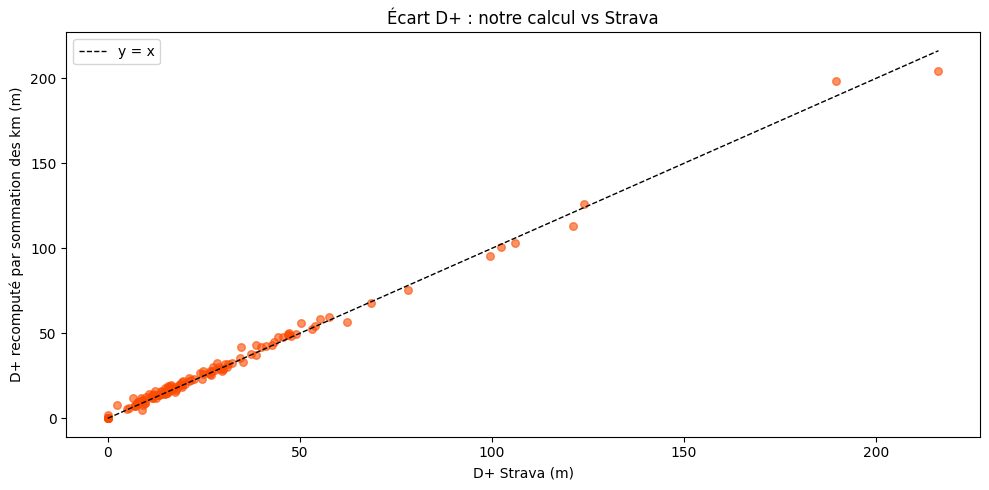


Biais médian : +3.9% (TODO connu : ~20%, à confirmer)


In [19]:
elev_agg = df_km.groupby("activity_id")["elev_gain_m"].sum().reset_index()
elev_agg.columns = ["activity_id", "elev_gain_km_sum"]

check_elev = elev_agg.merge(
    df_act[["id", "total_elevation_gain_m"]],
    left_on="activity_id", right_on="id", how="left"
)
# Écart relatif, en évitant division par zéro (sorties plates)
mask_positif = check_elev["total_elevation_gain_m"] > 5
check_elev.loc[mask_positif, "elev_diff_pct"] = (
    100 * (check_elev["elev_gain_km_sum"] - check_elev["total_elevation_gain_m"])
    / check_elev["total_elevation_gain_m"]
)

print("=== D+ recomputé vs Strava ===")
print(check_elev.loc[mask_positif, "elev_diff_pct"].describe().round(2))
print(f"(Analyse sur les {mask_positif.sum()} sorties avec D+ Strava > 5m)")

# Scatter plot
fig, ax = plt.subplots()
ax.scatter(check_elev["total_elevation_gain_m"], check_elev["elev_gain_km_sum"],
           alpha=0.6, s=30, color="#FC4C02")
lim = max(check_elev["total_elevation_gain_m"].max(),
          check_elev["elev_gain_km_sum"].max())
ax.plot([0, lim], [0, lim], "k--", linewidth=1, label="y = x")
ax.set_xlabel("D+ Strava (m)")
ax.set_ylabel("D+ recomputé par sommation des km (m)")
ax.set_title("Écart D+ : notre calcul vs Strava")
ax.legend()
plt.tight_layout()
plt.show()

# TODO connu : écart ~20% attendu. On vérifie.
biais = check_elev.loc[mask_positif, "elev_diff_pct"].median()
print(f"\nBiais médian : {biais:+.1f}% (TODO connu : ~20%, à confirmer)")

## 3. Impact elapsed vs moving sur l'allure

=== Écart d'allure (notre calcul vs Strava, en s/km) ===
count    131.0
mean      -5.0
std       12.6
min      -98.2
25%       -3.7
50%       -1.3
75%       -0.4
max        4.2
Name: pace_diff_sec, dtype: float64

=== Décomposition selon présence de pauses ===
           count  mean   std   min  25%  50%  75%  max
has_pause                                             
False       62.0  -2.3   4.6 -30.9 -2.5 -0.9 -0.3  0.5
True        69.0  -7.5  16.6 -98.2 -7.3 -1.8 -0.6  4.2


C:\Users\nordi\AppData\Local\Temp\ipykernel_2296\220936263.py:2: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  pace_agg = df_km.groupby("activity_id").apply(


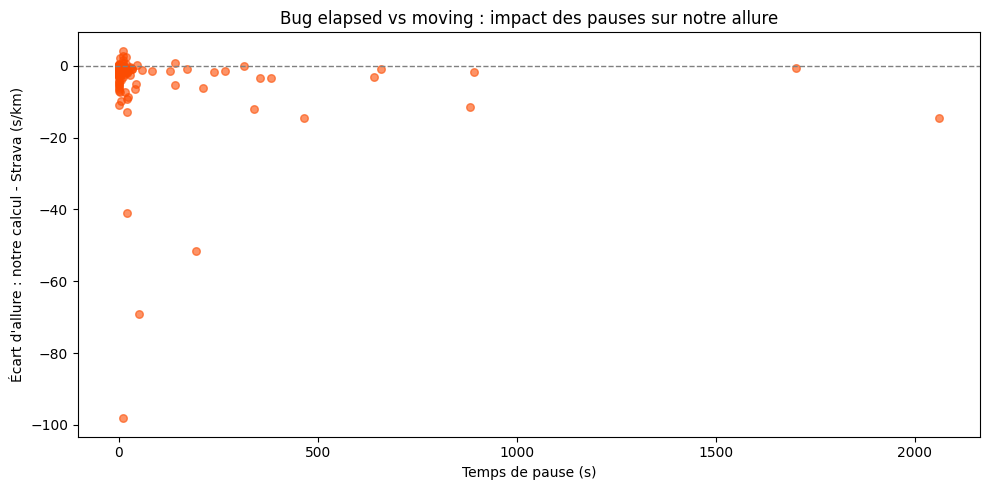


Corrélation pause_seconds ↔ écart d'allure : -0.075
Si positive et forte → notre allure ralentit avec les pauses,
ce qui confirme l'utilisation d'elapsed_time au lieu de moving_time.


In [20]:
# Allure moyenne pondérée par distance (comme Strava le fait)
pace_agg = df_km.groupby("activity_id").apply(
    lambda g: np.average(g["pace_min_per_km"], weights=g["km_distance_m"])
).reset_index()
pace_agg.columns = ["activity_id", "pace_km_weighted"]

check_pace = pace_agg.merge(
    df_act[["id", "pace_min_km", "pause_seconds", "moving_time_seconds", "distance_km"]],
    left_on="activity_id", right_on="id", how="left"
)
# Écart en secondes/km
check_pace["pace_diff_sec"] = (check_pace["pace_km_weighted"] - check_pace["pace_min_km"]) * 60

# Décomposition selon la présence de pauses
check_pace["has_pause"] = check_pace["pause_seconds"] > 0

print("=== Écart d'allure (notre calcul vs Strava, en s/km) ===")
print(check_pace["pace_diff_sec"].describe().round(1))

print("\n=== Décomposition selon présence de pauses ===")
print(check_pace.groupby("has_pause")["pace_diff_sec"].describe().round(1))

# Corrélation attendue : plus il y a de pauses, plus notre allure devrait s'écarter
# (si on utilise elapsed_time au lieu de moving_time)
sub = check_pace[check_pace["distance_km"] >= 1]  # exclure micro-sorties
fig, ax = plt.subplots()
ax.scatter(sub["pause_seconds"], sub["pace_diff_sec"],
           alpha=0.6, s=30, color="#FC4C02")
ax.axhline(0, color="grey", linestyle="--", linewidth=1)
ax.set_xlabel("Temps de pause (s)")
ax.set_ylabel("Écart d'allure : notre calcul - Strava (s/km)")
ax.set_title("Bug elapsed vs moving : impact des pauses sur notre allure")
plt.tight_layout()
plt.show()

corr = sub[["pause_seconds", "pace_diff_sec"]].corr().iloc[0, 1]
print(f"\nCorrélation pause_seconds ↔ écart d'allure : {corr:+.3f}")
print("Si positive et forte → notre allure ralentit avec les pauses,")
print("ce qui confirme l'utilisation d'elapsed_time au lieu de moving_time.")

### seuil de tolérance des pauses

In [21]:
# Combien de données garde-t-on selon le seuil de pause toléré ?
sub = check_pace[check_pace["distance_km"] >= 1].copy()

thresholds = [0, 15, 30, 60, 90, 120, 180, 300, 600, np.inf]
print("Seuil pause | N sorties gardées | Écart médian | 95e percentile | Écart max")
print("-" * 80)
for t in thresholds:
    keep = sub[sub["pause_seconds"] <= t]
    if len(keep) == 0:
        continue
    diffs = keep["pace_diff_sec"].abs()
    label = f"≤ {t:>4.0f}s" if np.isfinite(t) else "  tout "
    print(f"  {label}   |    {len(keep):>3}/{len(sub)}       |   "
          f"{diffs.median():>5.1f} s/km  |   {diffs.quantile(0.95):>6.1f} s/km   |  {diffs.max():>6.1f} s/km")

Seuil pause | N sorties gardées | Écart médian | 95e percentile | Écart max
--------------------------------------------------------------------------------
  ≤    0s   |     58/123       |     0.8 s/km  |      6.0 s/km   |    11.0 s/km
  ≤   15s   |     80/123       |     1.0 s/km  |      7.0 s/km   |    98.2 s/km
  ≤   30s   |     96/123       |     1.2 s/km  |      9.4 s/km   |    98.2 s/km
  ≤   60s   |    103/123       |     1.2 s/km  |      9.9 s/km   |    98.2 s/km
  ≤   90s   |    104/123       |     1.2 s/km  |      9.8 s/km   |    98.2 s/km
  ≤  120s   |    104/123       |     1.2 s/km  |      9.8 s/km   |    98.2 s/km
  ≤  180s   |    108/123       |     1.2 s/km  |      9.7 s/km   |    98.2 s/km
  ≤  300s   |    112/123       |     1.3 s/km  |     10.4 s/km   |    98.2 s/km
  ≤  600s   |    117/123       |     1.4 s/km  |     12.1 s/km   |    98.2 s/km
    tout    |    123/123       |     1.4 s/km  |     12.8 s/km   |    98.2 s/km


## 4. Validation externe (2-3 sorties à la main)

In [22]:
# Identifier les 4 sorties avec un split manquant
suspects = check[check["splits_diff"] == -1].merge(
    df_act[["id", "name", "pause_seconds", "start_date_local"]],
    left_on="activity_id", right_on="id", how="left"
)
print("=== Les 4 sorties avec un split manquant ===")
print(suspects[["activity_id", "name", "distance_km", "n_splits",
                "expected_splits", "pause_seconds"]].to_string(index=False))

# Zoom sur les splits de chaque
for aid in suspects["activity_id"]:
    print(f"\n--- Activité {aid} ---")
    print(df_km[df_km["activity_id"] == aid][
        ["km_index", "km_distance_m", "pace_min_per_km", "is_partial", "fraction_completed"]
    ].to_string(index=False))
    print(f"URL : https://www.strava.com/activities/{aid}")

=== Les 4 sorties avec un split manquant ===
 activity_id                            name  distance_km  n_splits  expected_splits  pause_seconds
 11779632537          Course à pied matinale       1.0017       1.0                2              6
 12532617749 Course à pied dans l'après-midi       4.0025       4.0                5              0
 15425210735           Course à pied de nuit      10.0034      10.0               11             33
 16079188605           Course à pied de nuit      10.0009      10.0               11            211

--- Activité 11779632537 ---
 km_index  km_distance_m  pace_min_per_km  is_partial  fraction_completed
        1          997.0         3.744567       False                 1.0
URL : https://www.strava.com/activities/11779632537

--- Activité 12532617749 ---
 km_index  km_distance_m  pace_min_per_km  is_partial  fraction_completed
        1          997.1         4.630094       False                0.25
        2          996.7         4.330959      

## 5. Décision & colonnes de qualité

In [23]:
import pandas as pd
from pathlib import Path

# Prendre n'importe quel fichier de streams (le 1er trouvé)
streams_dir = Path("../data/streams")
files = sorted(streams_dir.glob("streams_*.parquet"))
print(f"{len(files)} fichiers de streams trouvés dans {streams_dir.resolve()}")

if files:
    sample = pd.read_parquet(files[0])
    print(f"\nFichier lu : {files[0].name}")
    print(f"Colonnes : {sample.columns.tolist()}")
    print(f"\n{sample.head(3)}")

131 fichiers de streams trouvés dans C:\Users\nordi\David\Programmation\Python\StravAnalytics\data\streams

Fichier lu : streams_11346532154.parquet
Colonnes : ['time', 'distance', 'altitude']

   time  distance  altitude
0     0       0.0      51.0
1     1       0.4      51.0
2     2       0.8      51.0
